# Chatbot RAG para Consulta Normativa y Permanencia Estudiantil
### Integración de LLM (Gemini API), base vectorial Qdrant Cloud e interfaz gráfica Streamlit

**Institución:** Corporación Unificada Nacional de Educación Superior (CUN), Escuela de Ingeniería
**Programa:** Especialización en Inteligencia Artificial
**Asignatura:** Computación en la Nube | **Docente:** Hamilton Rivera Flor
**Actividad:** ACA N° 2, entrega acumulativa (continuación del ACA 1)
**Pilar:** Educación. Asistente de consulta académica, normatividad institucional y permanencia estudiantil.

**Integrantes:**

- Jhoan Ezequiel Hurtado Ramos
- Melania Martinez
- Anderson Rojas
- Camila Artega
- Monica Garavito

---

## Resumen

En el ACA 1 se construyó la base de conocimiento vectorial: los tres documentos normativos de la CUN y una muestra de perfiles del dataset UCI #697 se fragmentaron, se vectorizaron con `gemini-embedding-001` (768 dimensiones) y se almacenaron en **Qdrant Cloud**. En este ACA 2 se completa el ciclo *end-to-end* del sistema RAG:

1. **Conexión con la base vectorial (Paso 1).** El notebook se conecta a la colección del ACA 1 y verifica la recuperación semántica de los *Top-k* fragmentos.
2. **Configuración del LLM (Paso 2).** Se integra Google Gemini vía API con credenciales seguras y se justifican sus hiperparámetros.
3. **Pipeline RAG y *prompt engineering* (Paso 3).** Una plantilla de prompt combina la pregunta, la evidencia recuperada y el historial conversacional, y exige citas `[ID]`.
4. **Interfaz gráfica (Paso 4).** Una aplicación Streamlit ofrece un chat con historial y un módulo de gestión documental.
5. **Validación (Paso 5).** Siete casos de prueba miden la precisión contextual, la fidelidad de las citas, la latencia y la robustez ante consultas fuera de contexto.

### Pregunta orientadora
¿Cómo articular un modelo de lenguaje en la nube con una base de datos vectorial *serverless* para construir un chatbot RAG confiable, que responda en lenguaje natural sobre la normatividad de la CUN con respuestas fundamentadas en evidencia y sin alucinaciones?

---
## 1. Configuración del Entorno

Se instalan las librerías del cliente de Gemini (`google-genai`), el cliente de Qdrant (`qdrant-client`), el segmentador de texto (`langchain-text-splitters`) y el gestor de variables de entorno (`python-dotenv`).

**Gestión segura de credenciales.** Las claves **no se escriben en el código**. En Colab se registran en el panel **🔑 Secrets** (barra izquierda) con los nombres `QDRANT_URL`, `QDRANT_API_KEY` y `GEMINI_API_KEY`, y se habilita el acceso del notebook. En la ejecución local se leen de un archivo `.env`, y en Streamlit Cloud de `st.secrets`.

In [1]:
%pip install -q google-genai qdrant-client langchain-text-splitters python-dotenv pandas matplotlib ucimlrepo

### 1.1 Módulo `rag_core.py`

Toda la lógica del sistema RAG se concentra en un único módulo. **La aplicación Streamlit usa exactamente el mismo archivo**, lo que garantiza que el notebook y la interfaz gráfica se comporten igual. La celda siguiente crea el archivo en el entorno de Colab.

In [2]:
%%writefile rag_core.py
"""
rag_core.py - Núcleo del chatbot RAG (ACA 2 - Computación en la Nube, CUN)
==========================================================================
Pilar: Educación - normatividad institucional y permanencia estudiantil.

Este módulo lo usan tanto el notebook del ACA 2 como la app de Streamlit:

  PASO 1  Conexión con la base vectorial del ACA 1 (Qdrant Cloud).
  PASO 2  Configuración del LLM (Google Gemini vía API, credenciales seguras).
  PASO 3  Pipeline RAG: recuperación Top-k + prompt fundamentado + citas.
  PASO 4  Funciones de gestión documental que consume la interfaz gráfica.
  PASO 5  Utilidades de evaluación (latencia, citas válidas, abstención).

Las credenciales NUNCA se escriben en el código: se leen de variables de
entorno (.env), de los secrets de Streamlit o de los secrets de Colab.
"""
from __future__ import annotations

import os
import re
import time
import uuid

import pandas as pd
from google import genai
from google.genai import types
from langchain_text_splitters import RecursiveCharacterTextSplitter
from qdrant_client import QdrantClient
from qdrant_client.models import (
    Distance,
    FieldCondition,
    Filter,
    FilterSelector,
    MatchValue,
    PointStruct,
    VectorParams,
)

# ---------------------------------------------------------------------------
# Configuración general (debe coincidir con la indexación del ACA 1)
# ---------------------------------------------------------------------------
COLLECTION_NAME = "cun_educacion_permanencia_rag"
EMBED_MODEL = "gemini-embedding-001"   # mismo modelo de embeddings del ACA 1
EMBED_DIM = 768                        # misma dimensión del ACA 1
TIPO_NORMATIVO = "documento_normativo_institucional"
TIPO_PERFIL = "registro_tabular_uci_697"

# Modelos LLM candidatos, en orden de preferencia. Si Google retira uno,
# el sistema pasa automáticamente al siguiente disponible.
LLM_CANDIDATOS = [
    "gemini-3.1-flash-lite",   # mayor cuota en la capa gratuita y menor latencia (verificado en pruebas)
    "gemini-2.5-flash",
    "gemini-3.5-flash",
    "gemini-flash-latest",
]

# Hiperparámetros de generación (justificación en el notebook, sección 3)
HIPERPARAMETROS = {
    "temperature": 0.1,        # casi determinista: prioriza fidelidad sobre creatividad
    "top_p": 0.9,              # recorta tokens poco probables (menos "inventos")
    "max_output_tokens": 1024, # respuestas completas pero acotadas
}
TOP_K = 4                 # fragmentos que se inyectan en el prompt
UMBRAL_SIMILITUD = 0.45   # por debajo de este coseno el fragmento se descarta
TURNOS_HISTORIAL = 3      # turnos previos que se envían como memoria

SYSTEM_PROMPT = (
    "Eres el Asistente Normativo de la Corporación Unificada Nacional de Educación Superior (CUN), "
    "especializado en reglamento estudiantil, bienestar institucional, becas y permanencia estudiantil.\n"
    "REGLAS ESTRICTAS DE GENERACIÓN FUNDAMENTADA:\n"
    "1. Responde ÚNICAMENTE con la información explícita de los FRAGMENTOS DE EVIDENCIA suministrados.\n"
    "2. NO inventes ni extrapoles requisitos, promedios, porcentajes, montos, plazos ni conclusiones "
    "que no aparezcan textualmente en los fragmentos.\n"
    "3. Si la evidencia no contiene la respuesta, dilo expresamente con la frase: "
    "'La evidencia recuperada no contiene información sobre esa consulta.' y no agregues datos externos.\n"
    "4. Si la pregunta no tiene relación con la CUN, su normatividad o la permanencia estudiantil, "
    "indica amablemente que está fuera del alcance del asistente.\n"
    "5. Cita la fuente de cada afirmación o cifra con el identificador exacto entre corchetes, "
    "por ejemplo [DOC-reglamento-estudiantil-012] o [EST-0042]. Usa un corchete por cada ID.\n"
    "6. El HISTORIAL sirve solo para entender a qué se refiere el usuario; la evidencia manda.\n"
    "7. Redacta en español claro y breve, con viñetas cuando haya varios requisitos."
)

PATRON_CITA = re.compile(r"\[((?:DOC|EST)-[^\]]+)\]")
FRASE_ABSTENCION = "no contiene información"


# ---------------------------------------------------------------------------
# Credenciales (gestión segura)
# ---------------------------------------------------------------------------
def leer_secreto(nombre: str) -> str | None:
    """Busca una credencial en: variables de entorno/.env -> secrets de Streamlit -> secrets de Colab."""
    try:
        from dotenv import load_dotenv
        load_dotenv()
    except Exception:
        pass
    valor = os.getenv(nombre)
    if valor:
        return valor
    try:
        import streamlit as st
        if nombre in st.secrets:
            return st.secrets[nombre]
    except Exception:
        pass
    try:
        from google.colab import userdata
        return userdata.get(nombre)
    except Exception:
        return None


# ---------------------------------------------------------------------------
# PASO 1 - Conexión con la base vectorial
# ---------------------------------------------------------------------------
def conectar(qdrant_url: str, qdrant_api_key: str, gemini_api_key: str):
    """Crea los clientes de Qdrant Cloud y Gemini."""
    qdrant = QdrantClient(url=qdrant_url, api_key=qdrant_api_key, timeout=60)
    gemini = genai.Client(api_key=gemini_api_key)
    return qdrant, gemini


def estado_coleccion(qdrant: QdrantClient) -> dict:
    """Verifica que la colección del ACA 1 exista y devuelve sus características."""
    if not qdrant.collection_exists(COLLECTION_NAME):
        return {"existe": False, "fragmentos": 0, "dimension": None, "metrica": None}
    info = qdrant.get_collection(COLLECTION_NAME)
    vectores = info.config.params.vectors
    return {
        "existe": True,
        "fragmentos": qdrant.count(COLLECTION_NAME, exact=True).count,
        "dimension": getattr(vectores, "size", None),
        "metrica": str(getattr(vectores, "distance", "")).replace("Distance.", ""),
        "estado": str(info.status).replace("CollectionStatus.", ""),
    }


def crear_coleccion_si_no_existe(qdrant: QdrantClient) -> None:
    """Crea la colección (coseno, 768 dimensiones) y los índices de metadatos para filtros."""
    if not qdrant.collection_exists(COLLECTION_NAME):
        qdrant.create_collection(
            collection_name=COLLECTION_NAME,
            vectors_config=VectorParams(size=EMBED_DIM, distance=Distance.COSINE),
        )
    for campo in ("tipo_fuente", "documento", "documento_origen", "programa_academico", "nivel_riesgo_alerta"):
        try:
            qdrant.create_payload_index(COLLECTION_NAME, field_name=campo, field_schema="keyword")
        except Exception:
            pass  # el índice ya existe


def _con_reintento(funcion, max_reintentos: int = 4, espera_defecto: int = 30):
    """Ejecuta una llamada a Gemini reintentando si se agota la cuota gratuita (HTTP 429)."""
    for intento in range(1, max_reintentos + 1):
        try:
            return funcion()
        except Exception as err:
            msg = str(err)
            cuota_diaria = re.search(r"per ?day|PerDay|daily", msg, re.IGNORECASE)
            if ("429" in msg or "RESOURCE_EXHAUSTED" in msg) and intento < max_reintentos and not cuota_diaria:
                m = re.search(r"retry in ([0-9.]+)s", msg, re.IGNORECASE)
                time.sleep(int(float(m.group(1))) + 2 if m else espera_defecto)
            else:
                raise


def vectorizar(gemini, textos: list[str], task_type: str) -> list[list[float]]:
    """Convierte textos en vectores de 768 dimensiones (lotes de 50 por límite de la capa gratuita)."""
    vectores = []
    for i in range(0, len(textos), 50):
        lote = textos[i:i + 50]
        resp = _con_reintento(lambda: gemini.models.embed_content(
            model=EMBED_MODEL,
            contents=lote,
            config=types.EmbedContentConfig(task_type=task_type, output_dimensionality=EMBED_DIM),
        ), espera_defecto=62)
        vectores.extend(e.values for e in resp.embeddings)
    return vectores


def _filtro_tipo(tipo_fuente: str | None):
    if not tipo_fuente:
        return None
    return Filter(must=[FieldCondition(key="tipo_fuente", match=MatchValue(value=tipo_fuente))])


def recuperar(qdrant, gemini, pregunta: str, top_k: int = TOP_K, tipo_fuente: str | None = None,
              umbral: float = 0.0) -> list[dict]:
    """Recupera los Top-k fragmentos más similares (coseno) a la pregunta."""
    # Mismo formato de consulta que en el ACA 1 (RETRIEVAL_QUERY + prefijo de tarea)
    q_vec = vectorizar(gemini, [f"task: search result | query: {pregunta}"], "RETRIEVAL_QUERY")[0]
    hits = qdrant.query_points(
        collection_name=COLLECTION_NAME,
        query=q_vec,
        query_filter=_filtro_tipo(tipo_fuente),
        limit=top_k,
        with_payload=True,
    ).points
    fragmentos = []
    for rank, h in enumerate(hits, start=1):
        p = h.payload or {}
        es_doc = p.get("tipo_fuente") == TIPO_NORMATIVO
        fragmentos.append({
            "rank": rank,
            "similitud": round(float(h.score), 4),
            "id": p.get("id_documento", str(h.id)),
            "tipo_fuente": p.get("tipo_fuente", ""),
            "fuente": p.get("documento") if es_doc else f"Perfil UCI - {p.get('programa_academico', '')}",
            "ubicacion": (
                (" | ".join(x for x in (p.get("capitulo"), p.get("articulo")) if x) or "Disposición general")
                if es_doc else f"Riesgo: {p.get('nivel_riesgo_alerta', '')}"
            ),
            "texto": p.get("texto_semantico_rag", ""),
            "supera_umbral": float(h.score) >= umbral,
        })
    return fragmentos


# ---------------------------------------------------------------------------
# PASO 2 - Configuración del LLM
# ---------------------------------------------------------------------------
def modelos_disponibles(gemini) -> list[str]:
    """Devuelve los modelos candidatos que la API key realmente puede usar hoy."""
    try:
        nombres = {m.name.replace("models/", "") for m in gemini.models.list()}
        disponibles = [m for m in LLM_CANDIDATOS if m in nombres]
        return disponibles or LLM_CANDIDATOS
    except Exception:
        return LLM_CANDIDATOS


_MODELO_OK = None


def _generar(gemini, modelos: list[str], contenido: str, system: str, params: dict) -> tuple[str, str]:
    """Llama al LLM probando los modelos en orden. Devuelve (texto, modelo_usado)."""
    global _MODELO_OK
    ultimo_error = None
    # El último modelo que funcionó se prueba primero (evita repetir esperas en cada pregunta)
    orden = ([_MODELO_OK] if _MODELO_OK in modelos else []) + [m for m in modelos if m != _MODELO_OK]
    for modelo in orden:
        try:
            resp = _con_reintento(lambda: gemini.models.generate_content(
                model=modelo,
                contents=contenido,
                config=types.GenerateContentConfig(system_instruction=system, **params),
            ), max_reintentos=2, espera_defecto=15)
            texto = (resp.text or "").strip()
            if texto:
                _MODELO_OK = modelo
                return texto, modelo
        except Exception as err:  # modelo retirado (404) o cuota agotada: se prueba el siguiente
            ultimo_error = err
    raise RuntimeError(f"Ningún modelo LLM respondió. Último error: {ultimo_error}")


# ---------------------------------------------------------------------------
# PASO 3 - Pipeline RAG con historial conversacional
# ---------------------------------------------------------------------------
def _historial_a_texto(historial: list[dict], turnos: int = TURNOS_HISTORIAL) -> str:
    recientes = historial[-2 * turnos:]
    return "\n".join(
        f"{'Usuario' if m['role'] == 'user' else 'Asistente'}: {m['content'][:600]}" for m in recientes
    )


def reformular_pregunta(gemini, modelos, pregunta: str, historial: list[dict]) -> str:
    """Convierte una pregunta de seguimiento ('¿y si no cumplo eso?') en una pregunta autónoma
    para que la búsqueda vectorial encuentre los fragmentos correctos."""
    if not historial:
        return pregunta
    instruccion = (
        "Reescribe la ÚLTIMA pregunta del usuario como una pregunta autónoma y completa, "
        "usando el historial solo para resolver referencias (eso, ese, y si...). "
        "Devuelve únicamente la pregunta reescrita, sin explicaciones."
    )
    contenido = f"HISTORIAL:\n{_historial_a_texto(historial)}\n\nÚLTIMA PREGUNTA: {pregunta}"
    try:
        texto, _ = _generar(gemini, modelos, contenido, instruccion,
                            {"temperature": 0.0, "max_output_tokens": 200})
        return texto.splitlines()[0].strip() or pregunta
    except Exception:
        return pregunta


def construir_prompt(pregunta: str, fragmentos: list[dict], historial: list[dict]) -> str:
    """Plantilla de prompt: historial + fragmentos numerados con su ID + pregunta."""
    bloques = [
        f"[{f['id']}] Fuente: {f['fuente']} | Ubicación: {f['ubicacion']} | Similitud: {f['similitud']}\n"
        f"Contenido: {f['texto']}"
        for f in fragmentos
    ]
    evidencia = "\n\n---\n\n".join(bloques) if bloques else "(No se recuperó evidencia relevante.)"
    hist = _historial_a_texto(historial) if historial else "(sin historial)"
    return (
        f"HISTORIAL DE LA CONVERSACIÓN:\n{hist}\n\n"
        f"FRAGMENTOS DE EVIDENCIA (TOP-{len(fragmentos)}):\n{evidencia}\n\n"
        f"PREGUNTA DEL USUARIO:\n{pregunta}\n\n"
        "Responde siguiendo las reglas, citando [ID] en cada afirmación o cifra."
    )


def extraer_citas(texto: str) -> list[str]:
    citas = []
    for grupo in PATRON_CITA.findall(texto):
        for c in re.split(r"[,;]\s*", grupo):
            c = c.strip()
            if c and c not in citas:
                citas.append(c)
    return citas


def responder(qdrant, gemini, pregunta: str, historial: list[dict] | None = None,
              modelos: list[str] | None = None, top_k: int = TOP_K, tipo_fuente: str | None = None,
              umbral: float = UMBRAL_SIMILITUD, params: dict | None = None,
              usar_reformulacion: bool = True) -> dict:
    """Flujo RAG completo: (reformulación) -> recuperación Top-k -> filtro por umbral -> generación."""
    historial = historial or []
    modelos = modelos or LLM_CANDIDATOS
    params = {**HIPERPARAMETROS, **(params or {})}

    t0 = time.perf_counter()
    pregunta_busqueda = (
        reformular_pregunta(gemini, modelos, pregunta, historial) if usar_reformulacion else pregunta
    )
    t1 = time.perf_counter()
    todos = recuperar(qdrant, gemini, pregunta_busqueda, top_k, tipo_fuente, umbral)
    utiles = [f for f in todos if f["supera_umbral"]]
    t2 = time.perf_counter()

    if not utiles:
        # Ningún fragmento es suficientemente parecido: no se llama al LLM (evita alucinaciones)
        respuesta = ("La evidencia recuperada no contiene información sobre esa consulta. "
                     "Puedo ayudarte con temas del reglamento estudiantil, bienestar, becas y "
                     "permanencia en la CUN.")
        modelo_usado = "sin llamada (bajo umbral)"
    else:
        respuesta, modelo_usado = _generar(
            gemini, modelos, construir_prompt(pregunta, utiles, historial), SYSTEM_PROMPT, params
        )
    t3 = time.perf_counter()

    citas = extraer_citas(respuesta)
    ids_validos = {f["id"] for f in utiles}
    return {
        "pregunta": pregunta,
        "pregunta_busqueda": pregunta_busqueda,
        "respuesta": respuesta,
        "fragmentos": todos,
        "modelo": modelo_usado,
        "citas": citas,
        "citas_validas": [c for c in citas if c in ids_validos],
        "se_abstuvo": FRASE_ABSTENCION in respuesta.lower() or "fuera del alcance" in respuesta.lower(),
        "tiempos": {
            "reformulacion_s": round(t1 - t0, 2),
            "recuperacion_s": round(t2 - t1, 2),
            "generacion_s": round(t3 - t2, 2),
            "total_s": round(t3 - t0, 2),
        },
    }


# ---------------------------------------------------------------------------
# PASO 4 - Gestión documental (usado por la interfaz gráfica)
# ---------------------------------------------------------------------------
def todos_los_payloads(qdrant) -> pd.DataFrame:
    """Lee los metadatos de todos los fragmentos de la colección (sin vectores)."""
    filas, offset = [], None
    while True:
        puntos, offset = qdrant.scroll(COLLECTION_NAME, limit=256, offset=offset,
                                       with_payload=True, with_vectors=False)
        for p in puntos:
            filas.append({"point_id": str(p.id), **(p.payload or {})})
        if offset is None:
            break
    return pd.DataFrame(filas)


def resumen_documentos(df_payloads: pd.DataFrame) -> pd.DataFrame:
    """Agrupa los fragmentos por documento de origen."""
    if df_payloads.empty:
        return pd.DataFrame()
    df = df_payloads.copy()
    for col in ("documento_origen", "documento", "tipo_fuente", "fecha", "tema"):
        if col not in df:
            df[col] = None
    df["origen"] = df["documento_origen"].fillna("Perfiles estudiantiles (UCI #697)")
    df["documento"] = df["documento"].fillna(df["origen"])
    agg = (
        df.groupby("origen")
        .agg(
            documento=("documento", "first"),
            tipo_fuente=("tipo_fuente", "first"),
            fragmentos=("point_id", "count"),
            fecha=("fecha", "first"),
            tema=("tema", "first"),
        )
        .reset_index()
        .rename(columns={"origen": "archivo"})
        .sort_values("fragmentos", ascending=False)
    )
    return agg.fillna("")


# --- Fragmentación (misma lógica del ACA 1: por artículo y luego por tamaño) ---
_ORDINALES = r"(?:Primero|Segundo|Tercero|Cuarto|Quinto|Sexto|S[ée]ptimo|Octavo|Noveno|D[ée]cimo)"
RE_ART = re.compile(
    rf"^(?:#{{1,6}}\s*)?(?:\*\*)?\s*(?:ART[ÍI]CULO|Art)\.?\s*(\d+|{_ORDINALES})\s*[ºo°]?\s*[\.:\-–]",
    re.I,
)
RE_CAP = re.compile(r"^##\s+(?:LIBRO|CAP[ÍI]TULO)\b", re.I)


def _frontmatter(texto: str):
    metadatos, cuerpo = {}, texto
    if texto.startswith("---\n"):
        partes = texto.split("---\n", 2)
        if len(partes) == 3:
            for linea in partes[1].strip().splitlines():
                if ":" in linea:
                    k, v = linea.split(":", 1)
                    metadatos[k.strip()] = v.strip()
            cuerpo = partes[2].strip()
    return metadatos, cuerpo


def _limpiar(cuerpo: str) -> str:
    lineas = [l for l in cuerpo.splitlines() if not l.lstrip().startswith(">")]
    return "\n".join(l if RE_ART.match(l) else re.sub(r"^#{3,6}\s+", "", l) for l in lineas).strip()


def _dividir_por_articulos(cuerpo: str) -> list[dict]:
    secciones, capitulo, etiqueta, buffer = [], "", "Preámbulo", []
    lineas, i = cuerpo.splitlines(), 0

    def cerrar():
        txt = "\n".join(buffer).strip()
        if txt:
            secciones.append({"capitulo": capitulo, "articulo": etiqueta, "texto": txt})

    while i < len(lineas):
        l = lineas[i]
        if RE_CAP.match(l):
            cerrar(); buffer.clear()
            capitulo = l.lstrip("# ").strip()
            j = i + 1
            while j < len(lineas) and not lineas[j].strip():
                j += 1
            if (j < len(lineas) and len(lineas[j]) < 120
                    and not lineas[j].startswith(("**", "#")) and not RE_ART.match(lineas[j])):
                capitulo += " — " + lineas[j].strip()
                i = j
            etiqueta = "Preámbulo"
        elif RE_ART.match(l):
            cerrar(); buffer.clear()
            etiqueta = "Artículo " + RE_ART.match(l).group(1).capitalize()
            buffer.append(l)
        else:
            buffer.append(l)
        i += 1
    cerrar()
    return secciones


def fragmentar_documento(nombre_archivo: str, texto: str, chunk_size: int = 800,
                         chunk_overlap: int = 100) -> list[dict]:
    """Divide un documento .md/.txt en fragmentos con metadatos (configuración 800/100 del ACA 1)."""
    texto = texto.replace("\r\n", "\n")
    meta, cuerpo = _frontmatter(texto)
    stem = re.sub(r"\.(md|txt)$", "", nombre_archivo, flags=re.I)
    divisor = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size, chunk_overlap=chunk_overlap, separators=["\n\n", "\n", ". ", " ", ""]
    )
    fragmentos, n = [], 0
    for s in _dividir_por_articulos(_limpiar(cuerpo)):
        for frag in divisor.split_text(s["texto"]):
            n += 1
            contexto = " | ".join(x for x in (s["capitulo"], s["articulo"]) if x)
            fragmentos.append({
                "id_documento": f"DOC-{stem}-{n:03d}",
                "documento": meta.get("documento", stem),
                "institucion": meta.get("institucion", "CUN"),
                "tipo_fuente": meta.get("tipo_fuente", TIPO_NORMATIVO),
                "tema": meta.get("tema", "normatividad"),
                "fecha": meta.get("fecha", ""),
                "capitulo": s["capitulo"],
                "articulo": s["articulo"],
                "pilar": "Educación",
                "documento_origen": nombre_archivo,
                "texto_semantico_rag": f"{contexto}\n\n{frag}" if contexto else frag,
            })
    return fragmentos


def indexar_fragmentos(qdrant, gemini, fragmentos: list[dict]) -> int:
    """Vectoriza (RETRIEVAL_DOCUMENT) e inserta los fragmentos en Qdrant Cloud."""
    crear_coleccion_si_no_existe(qdrant)
    textos = [
        f"title: {f.get('documento', f.get('programa_academico', 'none'))} | text: {f['texto_semantico_rag']}"
        for f in fragmentos
    ]
    vectores = vectorizar(gemini, textos, "RETRIEVAL_DOCUMENT")
    puntos = [
        PointStruct(id=str(uuid.uuid5(uuid.NAMESPACE_URL, f["id_documento"])), vector=v, payload=f)
        for f, v in zip(fragmentos, vectores)
    ]
    for i in range(0, len(puntos), 64):
        qdrant.upsert(COLLECTION_NAME, points=puntos[i:i + 64])
    return len(puntos)


_CURSOS = {
    33: "Tecnologías de Producción de Biocombustibles", 171: "Diseño de Animación y Multimedia",
    8014: "Trabajo Social (Jornada nocturna)", 9003: "Agronomía", 9070: "Diseño de Comunicación",
    9085: "Enfermería Veterinaria", 9119: "Ingeniería Informática", 9130: "Equinocultura",
    9147: "Administración (Management)", 9238: "Trabajo Social", 9254: "Turismo", 9500: "Enfermería",
    9556: "Higiene Oral", 9670: "Gestión de Publicidad y Marketing", 9773: "Periodismo y Comunicación",
    9853: "Educación Básica", 9991: "Administración (Jornada nocturna)",
}
_ESTADO_CIVIL = {1: "soltero(a)", 2: "casado(a)", 3: "viudo(a)", 4: "divorciado(a)",
                 5: "unión libre (facto union)", 6: "separado(a) legalmente"}
_SI_NO = {1: "Sí", 0: "No"}
_RESULTADO = {"Dropout": "Deserción", "Enrolled": "Matriculado", "Graduate": "Graduado"}


def generar_perfiles_uci(df_uci: pd.DataFrame, muestra: int = 60, semilla: int = 42) -> list[dict]:
    """Recrea las fichas narrativas de estudiantes del ACA 1 (dataset UCI #697) con la misma
    regla de alerta temprana y una muestra estratificada por resultado académico."""
    filas = []
    for i, r in enumerate(df_uci.itertuples(index=False), start=1):
        g = dict(zip(df_uci.columns, r))
        ins1, apr1 = g["Curricular units 1st sem (enrolled)"], g["Curricular units 1st sem (approved)"]
        ins2, apr2 = g["Curricular units 2nd sem (enrolled)"], g["Curricular units 2nd sem (approved)"]
        tasa1 = round(apr1 / ins1 * 100, 1) if ins1 > 0 else 0.0
        tasa2 = round(apr2 / ins2 * 100, 1) if ins2 > 0 else 0.0
        al_dia, deudor = _SI_NO[g["Tuition fees up to date"]], _SI_NO[g["Debtor"]]
        factores = sum([al_dia == "No", deudor == "Sí", ins1 > 0 and tasa1 < 50,
                        ins2 > 0 and tasa2 < 50, ins1 == 0 and ins2 == 0])
        riesgo = "Alto" if factores >= 2 or al_dia == "No" else ("Medio" if factores == 1 else "Bajo")
        programa = _CURSOS.get(g["Course"], str(g["Course"]))
        jornada = "Diurna" if g["Daytime/evening attendance"] == 1 else "Nocturna"
        resultado = _RESULTADO.get(g["Target"], g["Target"])
        id_est = f"EST-{i:04d}"
        texto = (
            f"Ficha de seguimiento académico {id_est}: Estudiante de género "
            f"{'masculino' if g['Gender'] == 1 else 'femenino'}, {g['Age at enrollment']} años al ingreso, "
            f"estado civil {_ESTADO_CIVIL.get(g['Marital Status'], 'no registrado')}, matriculado en el programa de "
            f"{programa} (jornada {jornada.lower()}). Perfil socioeconómico y financiero: "
            f"desplazado={_SI_NO[g['Displaced']]}, becado={_SI_NO[g['Scholarship holder']]}, deudor={deudor}, "
            f"matrícula al día={al_dia}. Desempeño 1er semestre: {apr1} de {ins1} unidades aprobadas ({tasa1}%) "
            f"con promedio {round(g['Curricular units 1st sem (grade)'], 2)}/20. Desempeño 2do semestre: {apr2} de "
            f"{ins2} unidades aprobadas ({tasa2}%) con promedio {round(g['Curricular units 2nd sem (grade)'], 2)}/20. "
            f"Nivel de alerta temprana: {riesgo}. Resultado académico final registrado: {resultado}."
        )
        filas.append({
            "id_documento": id_est, "tipo_fuente": TIPO_PERFIL, "pilar": "Educación",
            "programa_academico": programa, "jornada": jornada, "matricula_al_dia": al_dia,
            "deudor": deudor, "becado": _SI_NO[g["Scholarship holder"]], "nivel_riesgo_alerta": riesgo,
            "estado_estudiante": resultado, "texto_semantico_rag": texto,
        })
    df = pd.DataFrame(filas)
    df = (df.groupby("estado_estudiante", group_keys=False)
            .apply(lambda x: x.sample(min(len(x), muestra // 3), random_state=semilla))
            .reset_index(drop=True))
    return df.to_dict(orient="records")


def eliminar_documento(qdrant, nombre_archivo: str) -> None:
    """Elimina de la colección todos los fragmentos de un documento."""
    crear_coleccion_si_no_existe(qdrant)  # asegura el índice del campo documento_origen
    qdrant.delete(
        COLLECTION_NAME,
        points_selector=FilterSelector(filter=Filter(must=[
            FieldCondition(key="documento_origen", match=MatchValue(value=nombre_archivo))
        ])),
    )


# ---------------------------------------------------------------------------
# PASO 5 - Casos de prueba para la evaluación
# ---------------------------------------------------------------------------
CASOS_PRUEBA = [
    {"caso": "C1 Becas", "tipo": "normativa",
     "pregunta": "¿Qué promedio necesito para obtener una beca por excelencia académica y de qué porcentaje es?"},
    {"caso": "C2 Calidad de estudiante", "tipo": "normativa",
     "pregunta": "¿En qué casos se pierde la calidad de estudiante en la CUN?"},
    {"caso": "C3 Seguimiento (historial)", "tipo": "seguimiento",
     "pregunta": "¿Y qué pasa si mi promedio queda por debajo de la nota mínima aprobatoria?"},
    {"caso": "C4 Bienestar", "tipo": "normativa",
     "pregunta": "¿Qué servicios o dimensiones ofrece Bienestar Institucional para apoyar la permanencia?"},
    {"caso": "C5 Perfiles UCI", "tipo": "perfiles",
     "pregunta": "Perfil de estudiante de Ingeniería Informática con matrícula en mora y baja aprobación en primer semestre"},
    {"caso": "C6 Dato inexistente", "tipo": "fuera_de_contexto",
     "pregunta": "¿Cuánto paga la CUN de auxilio mensual de transporte en helicóptero?"},
    {"caso": "C7 Tema ajeno", "tipo": "fuera_de_contexto",
     "pregunta": "¿Quién ganó el mundial de fútbol de 2022?"},
]


def evaluar(qdrant, gemini, modelos=None, casos=None, pausa_s: float = 2.0, **kwargs):
    """Ejecuta los casos de prueba y mide precisión contextual, fidelidad de citas,
    abstención ante consultas fuera de contexto y latencia.
    El caso de 'seguimiento' reutiliza la pregunta y respuesta anterior como historial."""
    casos = casos or CASOS_PRUEBA
    filas, resultados, previo = [], [], None
    for caso in casos:
        historial = []
        if caso["tipo"] == "seguimiento" and previo:
            historial = [{"role": "user", "content": previo["pregunta"]},
                         {"role": "assistant", "content": previo["respuesta"]}]
        tipo_fuente = TIPO_PERFIL if caso["tipo"] == "perfiles" else None
        r = responder(qdrant, gemini, caso["pregunta"], historial=historial, modelos=modelos,
                      tipo_fuente=tipo_fuente, **kwargs)
        esperado_abstener = caso["tipo"] == "fuera_de_contexto"
        n_citas = len(r["citas"])
        filas.append({
            "Caso": caso["caso"],
            "Tipo": caso["tipo"],
            "Similitud Top-1": r["fragmentos"][0]["similitud"] if r["fragmentos"] else None,
            "Fragmentos útiles": sum(f["supera_umbral"] for f in r["fragmentos"]),
            "Citas": n_citas,
            "Citas válidas (%)": round(100 * len(r["citas_validas"]) / n_citas, 1) if n_citas else None,
            "Se abstuvo": r["se_abstuvo"],
            "Comportamiento correcto": r["se_abstuvo"] if esperado_abstener else (not r["se_abstuvo"] and n_citas > 0),
            "Recuperación (s)": r["tiempos"]["recuperacion_s"],
            "Generación (s)": r["tiempos"]["generacion_s"],
            "Total (s)": r["tiempos"]["total_s"],
            "Modelo": r["modelo"],
        })
        resultados.append(r)
        previo = r
        time.sleep(pausa_s)  # respeta la cuota gratuita de Gemini
    return pd.DataFrame(filas), resultados

Writing rag_core.py


In [3]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

import rag_core as rag

pd.set_option("display.max_colwidth", 120)

QDRANT_URL = rag.leer_secreto("QDRANT_URL")
QDRANT_API_KEY = rag.leer_secreto("QDRANT_API_KEY")
GEMINI_API_KEY = rag.leer_secreto("GEMINI_API_KEY")

print("Estado de las credenciales (no se imprime su valor):")
for nombre, valor in [("QDRANT_URL", QDRANT_URL), ("QDRANT_API_KEY", QDRANT_API_KEY), ("GEMINI_API_KEY", GEMINI_API_KEY)]:
    print(f" - {nombre}: {'configurada' if valor else 'FALTA'}")

Estado de las credenciales (no se imprime su valor):
 - QDRANT_URL: configurada
 - QDRANT_API_KEY: configurada
 - GEMINI_API_KEY: configurada


---
## 2. Paso 1: Conexión y Recuperación de la Base Vectorial

Se crea el cliente de **Qdrant Cloud** y se verifica que la colección `cun_educacion_permanencia_rag` del ACA 1 siga disponible, con su número de fragmentos, la dimensión de los vectores y la métrica de distancia.

In [4]:
qdrant, gemini = rag.conectar(QDRANT_URL, QDRANT_API_KEY, GEMINI_API_KEY)
estado = rag.estado_coleccion(qdrant)
display(pd.DataFrame([estado]))

,existe,fragmentos,dimension,metrica,estado
0,True,360,768,Cosine,green


### 2.1 Reconstrucción de la colección (solo si es necesario)

Los clústeres gratuitos de Qdrant Cloud se suspenden tras un periodo de inactividad. Si la colección no existe o está vacía, la siguiente celda la reconstruye con los tres documentos normativos de la CUN (`data/docs/`) y las 60 fichas de estudiantes del dataset UCI #697, usando la **misma fragmentación del ACA 1** (por artículo y luego por tamaño, `chunk_size = 800` y `chunk_overlap = 100`) y el mismo modelo de embeddings. Si la colección está activa, la celda no modifica nada.

In [5]:
import zipfile

if not estado["existe"] or estado["fragmentos"] == 0:
    if not Path("data/docs").exists():
        from google.colab import files
        print("Sube el archivo data.zip con los documentos normativos de la CUN:")
        files.upload()
        with zipfile.ZipFile("data.zip") as z:
            z.extractall(".", members=[m for m in z.namelist() if not m.startswith("__MACOSX")])
    total = 0
    for ruta in sorted(Path("data/docs").glob("*.md")):
        fragmentos = rag.fragmentar_documento(ruta.name, ruta.read_text(encoding="utf-8"))
        total += rag.indexar_fragmentos(qdrant, gemini, fragmentos)
        print(f"{ruta.name}: {len(fragmentos)} fragmentos indexados")
    # Perfiles estudiantiles del dataset UCI #697 (misma muestra estratificada de 60 fichas del ACA 1)
    from ucimlrepo import fetch_ucirepo
    uci = fetch_ucirepo(id=697)
    df_uci = pd.concat([uci.data.features, uci.data.targets], axis=1)
    perfiles = rag.generar_perfiles_uci(df_uci, muestra=60)
    total += rag.indexar_fragmentos(qdrant, gemini, perfiles)
    print(f"Perfiles estudiantiles UCI #697: {len(perfiles)} fichas indexadas")
    estado = rag.estado_coleccion(qdrant)
    print(f"Colección reconstruida: {estado['fragmentos']} fragmentos.")
else:
    print(f"La colección del ACA 1 está activa con {estado['fragmentos']} fragmentos. No es necesario reindexar.")

La colección del ACA 1 está activa con 360 fragmentos. No es necesario reindexar.


### 2.2 Inventario documental de la base vectorial

Se leen los metadatos (*payload*) de todos los puntos almacenados, sin descargar los vectores, para verificar qué documentos y cuántos fragmentos contiene la base.

,archivo,documento,tipo_fuente,fragmentos,fecha,tema
2,reglamento-estudiantil.md,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,documento_normativo_institucional,178,2023-09-01,académico / permanencia / matrícula / evaluación
1,reglamento-bienestar.md,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,documento_normativo_institucional,104,2018-06-29,bienestar / permanencia / becas / acompañamiento
0,Perfiles estudiantiles (UCI #697),Perfiles estudiantiles (UCI #697),registro_tabular_uci_697,60,,
3,resolucion-007-2024-becas-rendimiento-academico.md,Resolución Rectoral No. 007 de 2024,documento_normativo_institucional,18,2024-06-25,financiero / becas


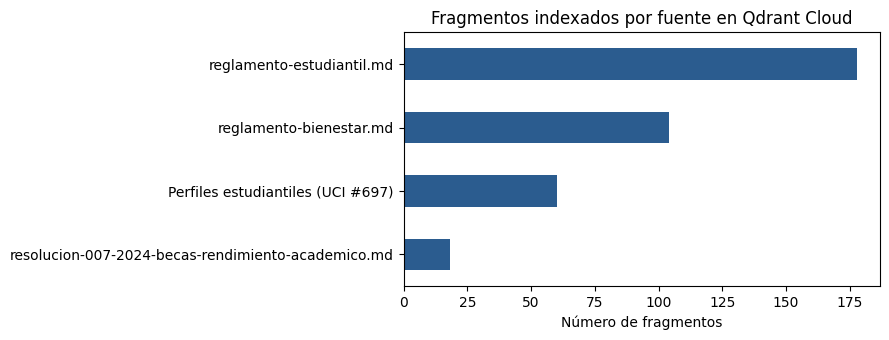

In [6]:
df_payloads = rag.todos_los_payloads(qdrant)
resumen_docs = rag.resumen_documentos(df_payloads)
display(resumen_docs)

ax = resumen_docs.set_index("archivo")["fragmentos"].sort_values().plot(kind="barh", color="#2b5c8f", figsize=(9, 3.5))
ax.set_title("Fragmentos indexados por fuente en Qdrant Cloud")
ax.set_xlabel("Número de fragmentos")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### 2.3 Recuperación semántica Top-k

La consulta se vectoriza con `task_type = RETRIEVAL_QUERY` y Qdrant devuelve los `k = 4` fragmentos con mayor **similitud coseno**. Esta etapa todavía no usa el LLM: solo comprueba que la búsqueda trae evidencia pertinente.

In [7]:
consulta = "¿Qué promedio necesito para obtener una beca por excelencia académica?"
t0 = time.perf_counter()
top_k = rag.recuperar(qdrant, gemini, consulta, top_k=4)
print(f"Consulta: {consulta}\nTiempo de recuperación: {time.perf_counter() - t0:.2f} s")
display(pd.DataFrame(top_k)[["rank", "similitud", "id", "fuente", "ubicacion", "texto"]])

Consulta: ¿Qué promedio necesito para obtener una beca por excelencia académica?
Tiempo de recuperación: 0.59 s


,rank,similitud,id,fuente,ubicacion,texto
0,1,0.7423,DOC-reglamento-bienestar-066,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 32,CAPÍTULO SEPTIMO | Artículo 32\n\n**ARTICULO 32. BECAS DE EXCELENCIA ACADÉMICA:** La Corporación en aras de promover...
1,2,0.7357,DOC-resolucion-007-2024-becas-rendimiento-academico-007,Resolución Rectoral No. 007 de 2024,Preámbulo,"Preámbulo\n\nQue el artículo 31 del Reglamento de Bienestar dispone que, en aras de promover la excelencia académica..."
2,3,0.7321,DOC-reglamento-bienestar-067,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 32,CAPÍTULO SEPTIMO | Artículo 32\n\n. El Líder de Registro y Control Académico entregara de manera oficial el listado ...
3,4,0.7279,DOC-resolucion-007-2024-becas-rendimiento-academico-012,Resolución Rectoral No. 007 de 2024,Artículo Tercero,Artículo Tercero\n\n**Artículo Tercero.** Las becas por excelencia académica serán asignadas por parte de los Coordi...


---
## 3. Paso 2: Selección y Configuración del LLM

### Justificación del modelo

Se eligió la **opción Cloud API con Google Gemini**, recomendada en la guía de la actividad, por cuatro razones:

- **Continuidad tecnológica.** Los embeddings del ACA 1 ya se generaron con Gemini, así que se usa una sola API key y un solo proveedor.
- **Costo cero.** La capa gratuita de Google AI Studio cubre el volumen de un proyecto académico, sin GPU ni servidores propios.
- **Baja latencia y buen desempeño en español.** Los modelos *Flash* están optimizados para respuestas rápidas.
- **Despliegue sencillo.** Al no requerir un modelo local (Ollama/Gemma), la app funciona en Streamlit Community Cloud, que no tiene GPU.

El código prueba una **lista de modelos en orden de preferencia** (`rag.LLM_CANDIDATOS`). Si Google retira un modelo, el sistema usa automáticamente el siguiente disponible.

### Hiperparámetros

| Hiperparámetro | Valor | Justificación |
|---|---|---|
| `temperature` | 0.1 | Respuestas casi deterministas: en un asistente normativo importa la fidelidad, no la creatividad. |
| `top_p` | 0.9 | Descarta los tokens menos probables y reduce la generación de datos no respaldados. |
| `max_output_tokens` | 1024 | Permite enumerar varios requisitos sin respuestas excesivamente largas. |
| `top_k` (recuperación) | 4 | Aporta evidencia suficiente sin saturar el prompt con fragmentos poco relevantes. |
| Umbral de similitud | 0.45 | Si ningún fragmento supera este valor, no se llama al LLM y se responde que no hay evidencia. |
| Turnos de historial | 3 | Memoria suficiente para preguntas de seguimiento sin aumentar demasiado el prompt. |

In [8]:
modelos = rag.modelos_disponibles(gemini)
print("Modelos candidatos disponibles para esta API key:", modelos)
print("Hiperparámetros de generación:", rag.HIPERPARAMETROS)

t0 = time.perf_counter()
texto, modelo_usado = rag._generar(gemini, modelos, "Responde únicamente con la palabra: CONECTADO",
                                   "Eres un verificador de conexión.", {"temperature": 0.0, "max_output_tokens": 10})
print(f"\nPrueba de conexión con el LLM -> modelo: {modelo_usado} | respuesta: {texto} | {time.perf_counter() - t0:.2f} s")

Modelos candidatos disponibles para esta API key: ['gemini-3.1-flash-lite', 'gemini-2.5-flash', 'gemini-3.5-flash', 'gemini-flash-latest']
Hiperparámetros de generación: {'temperature': 0.1, 'top_p': 0.9, 'max_output_tokens': 1024}

Prueba de conexión con el LLM -> modelo: gemini-3.1-flash-lite | respuesta: CONECTADO | 0.51 s


---
## 4. Paso 3: Canalización RAG y Prompt Engineering

### 4.1 Plantilla de prompt

El prompt tiene dos partes:

- **Instrucción de sistema (`SYSTEM_PROMPT`).** Define el rol del asistente y siete reglas: responder solo con la evidencia, no inventar cifras, abstenerse cuando no hay información, rechazar temas ajenos, citar cada afirmación con su `[ID]`, usar el historial solo para resolver referencias y redactar en español claro.
- **Mensaje de usuario (`construir_prompt`).** Une el historial reciente, los fragmentos recuperados (cada uno con su ID, fuente, ubicación y similitud) y la pregunta.

El flujo completo de `rag.responder()` es: **reformulación de la pregunta con el historial → recuperación Top-k → filtro por umbral → generación → validación de citas**.

In [9]:
print("=== INSTRUCCIÓN DE SISTEMA ===\n")
print(rag.SYSTEM_PROMPT)
print("\n=== EJEMPLO DE PROMPT DE USUARIO (recortado) ===\n")
print(rag.construir_prompt(consulta, top_k[:2], [])[:1500], "...")

=== INSTRUCCIÓN DE SISTEMA ===

Eres el Asistente Normativo de la Corporación Unificada Nacional de Educación Superior (CUN), especializado en reglamento estudiantil, bienestar institucional, becas y permanencia estudiantil.
REGLAS ESTRICTAS DE GENERACIÓN FUNDAMENTADA:
1. Responde ÚNICAMENTE con la información explícita de los FRAGMENTOS DE EVIDENCIA suministrados.
2. NO inventes ni extrapoles requisitos, promedios, porcentajes, montos, plazos ni conclusiones que no aparezcan textualmente en los fragmentos.
3. Si la evidencia no contiene la respuesta, dilo expresamente con la frase: 'La evidencia recuperada no contiene información sobre esa consulta.' y no agregues datos externos.
4. Si la pregunta no tiene relación con la CUN, su normatividad o la permanencia estudiantil, indica amablemente que está fuera del alcance del asistente.
5. Cita la fuente de cada afirmación o cifra con el identificador exacto entre corchetes, por ejemplo [DOC-reglamento-estudiantil-012] o [EST-0042]. Usa un

### 4.2 Respuestas fundamentadas con citas

La función `mostrar()` presenta la respuesta generada, las citas utilizadas, los tiempos de cada etapa y la tabla de fragmentos recuperados.

In [10]:
def mostrar(r):
    t = r["tiempos"]
    reformulada = (f"*Búsqueda reformulada:* {r['pregunta_busqueda']}\n\n"
                   if r["pregunta_busqueda"] != r["pregunta"] else "")
    display(Markdown(
        f"---\n**Pregunta:** {r['pregunta']}\n\n{reformulada}"
        f"**Respuesta ({r['modelo']}):**\n\n{r['respuesta']}\n\n"
        f"⏱️ Total **{t['total_s']} s** (recuperación {t['recuperacion_s']} s · generación {t['generacion_s']} s) · "
        f"citas válidas **{len(r['citas_validas'])}/{len(r['citas'])}**"
    ))
    display(pd.DataFrame(r["fragmentos"])[["rank", "similitud", "id", "fuente", "ubicacion", "supera_umbral"]])


r1 = rag.responder(qdrant, gemini, "¿Qué promedio necesito para obtener una beca por excelencia académica y de qué porcentaje es?", modelos=modelos)
mostrar(r1)

---
**Pregunta:** ¿Qué promedio necesito para obtener una beca por excelencia académica y de qué porcentaje es?

**Respuesta (gemini-3.1-flash-lite):**

Para obtener una beca por excelencia académica en la CUN, se requiere cumplir con los siguientes promedios históricos y porcentajes de descuento sobre el valor ordinario de la matrícula:

*   **Promedio histórico igual o superior a 4.5:** Se otorga una beca del **50%** del valor ordinario de la matrícula [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].
*   **Promedio histórico igual o superior a 4.3:** Se otorga una beca del **25%** del valor ordinario de la matrícula [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].

Adicionalmente, para acceder a este beneficio, se deben cumplir los siguientes requisitos:
*   Estar cursando del segundo semestre académico en adelante [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].
*   Haber cursado el máximo de créditos permitido por periodo académico [DOC-reglamento-bienestar-067].
*   No haber cancelado ni reprobado ningún crédito [DOC-reglamento-bienestar-067].
*   Encontrarse a paz y salvo financieramente en el periodo vigente [DOC-reglamento-bienestar-067].

⏱️ Total **1.71 s** (recuperación 0.45 s · generación 1.26 s) · citas válidas **3/3**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.7432,DOC-reglamento-bienestar-066,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 32,True
1,2,0.7381,DOC-resolucion-007-2024-becas-rendimiento-academico-007,Resolución Rectoral No. 007 de 2024,Preámbulo,True
2,3,0.7361,DOC-reglamento-bienestar-067,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 32,True
3,4,0.7222,DOC-reglamento-bienestar-079,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 34,True


In [11]:
r2 = rag.responder(qdrant, gemini, "¿En qué casos se pierde la calidad de estudiante en la CUN?", modelos=modelos)
mostrar(r2)

---
**Pregunta:** ¿En qué casos se pierde la calidad de estudiante en la CUN?

**Respuesta (gemini-3.1-flash-lite):**

La calidad de estudiante en la CUN se pierde en los siguientes eventos:

*   Cuando no se renueva la matrícula dentro de los plazos establecidos por la Institución, de acuerdo con el calendario académico, o cuando se permanece inactivo académicamente por más de tres años [DOC-reglamento-estudiantil-005].
*   Cuando se procede a la cancelación de la matrícula por razones académicas o disciplinarias, previo el trámite del debido proceso [DOC-reglamento-estudiantil-005].
*   Cuando el estudiante se retira voluntariamente de la Institución [DOC-reglamento-estudiantil-005].
*   Cuando se ha finalizado la totalidad del plan de estudios para el cual se matriculó [DOC-reglamento-estudiantil-005].

⏱️ Total **1.73 s** (recuperación 0.43 s · generación 1.3 s) · citas válidas **1/1**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.7436,DOC-reglamento-estudiantil-024,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO QUINTO — RETIROS Y APLAZAMIENTOS | Artículo 14,True
1,2,0.7318,DOC-reglamento-estudiantil-005,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO PRIMERO — OBJETO Y DE LA CALIDAD DE ESTUDIANTE | Artículo 3,True
2,3,0.7282,DOC-reglamento-estudiantil-004,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO PRIMERO — OBJETO Y DE LA CALIDAD DE ESTUDIANTE | Artículo 2,True
3,4,0.7140,DOC-reglamento-estudiantil-007,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO SEGUNDO — REQUISITOS DE INSCRIPCIÓN Y ADMISIÓN | Artículo 4,True


### 4.3 Diálogo con historial conversacional

Se simula una conversación de tres turnos. La segunda y la tercera pregunta dependen de la anterior ("¿y si...?"). El sistema las **reformula como preguntas autónomas** antes de buscar en Qdrant, de modo que la recuperación encuentra los artículos correctos.

In [12]:
historial = []
for pregunta in [
    "¿Qué es la prueba académica según el reglamento estudiantil?",
    "¿Y qué pasa si no la supero?",
    "¿Puedo pedir apoyo a Bienestar en esa situación?",
]:
    r = rag.responder(qdrant, gemini, pregunta, historial=historial, modelos=modelos)
    mostrar(r)
    historial += [{"role": "user", "content": pregunta}, {"role": "assistant", "content": r["respuesta"]}]
    time.sleep(2)

---
**Pregunta:** ¿Qué es la prueba académica según el reglamento estudiantil?

**Respuesta (gemini-3.1-flash-lite):**

La evidencia recuperada no contiene información sobre una definición general de "prueba académica". Sin embargo, el Reglamento Estudiantil define los siguientes tipos específicos de pruebas:

*   **Prueba de suficiencia:** Es aquella que se practica a aspirantes o estudiantes para aprobar asignaturas o créditos académicos cuando declaran tener dominio previo de conocimientos, destrezas, competencias y habilidades, permitiéndoles ser eximidos de cursarlas [DOC-reglamento-estudiantil-079].
*   **Prueba de admisión:** Es la que la Institución puede señalar a los aspirantes a un programa académico [DOC-reglamento-estudiantil-068].
*   **Prueba final:** Es el examen realizado al terminar un periodo académico o interperiodo, con el propósito de verificar y validar el desarrollo integral del estudiante en las competencias de la asignatura y el programa [DOC-reglamento-estudiantil-070].
*   **Prueba de sustentación:** Es el mecanismo mediante el cual se cuantifica el rendimiento académico del estudiante en una escala de cero punto uno (0.1) a cinco punto cero (5.0) [DOC-reglamento-estudiantil-089].

⏱️ Total **1.21 s** (recuperación 0.26 s · generación 0.95 s) · citas válidas **4/4**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.7264,DOC-reglamento-estudiantil-079,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 43,True
1,2,0.7249,DOC-reglamento-estudiantil-068,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 38,True
2,3,0.7089,DOC-reglamento-estudiantil-070,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 40,True
3,4,0.7057,DOC-reglamento-estudiantil-089,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 50,True


---
**Pregunta:** ¿Y qué pasa si no la supero?

*Búsqueda reformulada:* ¿Qué sucede si un estudiante no supera la prueba de suficiencia según el reglamento estudiantil?

**Respuesta (gemini-3.1-flash-lite):**

La evidencia recuperada no contiene información sobre las consecuencias de no superar una prueba de suficiencia.

No obstante, respecto a otras evaluaciones, el reglamento establece lo siguiente:

*   **Prueba supletoria:** Si el estudiante no presenta la prueba en la fecha y hora fijadas, perderá el derecho a presentarla y se le reportará una calificación de cero punto uno (0.1) [DOC-reglamento-estudiantil-078].
*   **Pérdida reiterada de asignaturas:** Si un estudiante debe cursar por tercera vez la misma asignatura, el Comité del Programa académico revisará el caso y establecerá las condiciones que el estudiante debe cumplir, previa solicitud por escrito ante la Oficina del Programa [DOC-reglamento-estudiantil-088].

⏱️ Total **1.62 s** (recuperación 0.33 s · generación 0.81 s) · citas válidas **2/2**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.7221,DOC-reglamento-estudiantil-079,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 43,True
1,2,0.7181,DOC-reglamento-estudiantil-030,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO SÉPTIMO — DE LAS TRANSFERENCIAS Y REINTEGROS | Artículo 17,True
2,3,0.7131,DOC-reglamento-estudiantil-078,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 42,True
3,4,0.6975,DOC-reglamento-estudiantil-088,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 49,True


---
**Pregunta:** ¿Puedo pedir apoyo a Bienestar en esa situación?

*Búsqueda reformulada:* ¿Puedo pedir apoyo a Bienestar si no supero una prueba de suficiencia?

**Respuesta (gemini-3.1-flash-lite):**

La evidencia recuperada no contiene información sobre si puedes solicitar apoyo a Bienestar específicamente por no superar una prueba de suficiencia.

Sin embargo, el Reglamento de Bienestar Institucional establece que los representantes estudiantiles cuentan con los siguientes beneficios relacionados con pruebas:

*   Pueden presentar exámenes o pruebas de manera extemporánea sin pagar derechos de supletorios, siempre que los aplazamientos se deban a su vinculación como representante y cuenten con autorización previa de la unidad académica o administrativa correspondiente [DOC-reglamento-bienestar-054].

⏱️ Total **2.09 s** (recuperación 0.23 s · generación 1.4 s) · citas válidas **1/1**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.6798,DOC-reglamento-bienestar-054,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPITULO SEXTO — ESTATUTARIOS. | Artículo 26,True
1,2,0.6496,DOC-reglamento-bienestar-102,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO OCTAVO | Artículo 47,True
2,3,0.6421,DOC-reglamento-estudiantil-079,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 43,True
3,4,0.6412,DOC-reglamento-bienestar-068,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 32,True


---
## 5. Paso 4: Interfaz Gráfica (Streamlit)

La aplicación `app.py` usa el mismo módulo `rag_core.py` y se despliega en **Streamlit Community Cloud**. Tiene cuatro pestañas:

| Pestaña | Función |
|---|---|
| 💬 **Chat** | Chat con historial conversacional. Cada respuesta muestra la latencia, el modelo usado, las citas válidas y un desplegable con los fragmentos recuperados y su similitud. |
| 📚 **Gestión documental** | Métricas de la colección, tabla de documentos, explorador de fragmentos y metadatos, prueba de recuperación sin LLM, carga de nuevos documentos `.md`/`.txt` y eliminación de documentos. |
| 🧪 **Evaluación** | Ejecuta los casos de prueba del Paso 5 desde la interfaz. |
| 🏗️ **Arquitectura** | Diagrama del flujo RAG y del stack tecnológico. |

En la barra lateral se configuran el modelo, la temperatura, el Top-k, el umbral de similitud y el tipo de fuente a consultar.

**Enlaces:**
- Aplicación: https://asistente-cun-rag.streamlit.app/
- Repositorio: https://github.com/monicagaravito/aca2-chatbot-rag-cun

---
## 6. Paso 5: Validación Integral y Optimización

Se ejecutan siete casos de prueba (`rag.CASOS_PRUEBA`):

| Tipo | Casos | Comportamiento esperado |
|---|---|---|
| Normativa | C1 Becas, C2 Calidad de estudiante, C4 Bienestar | Responder con citas válidas a los reglamentos. |
| Seguimiento | C3 | Usar el historial de C2 para entender "¿y qué pasa si...?". |
| Perfiles | C5 | Recuperar perfiles del dataset UCI #697 (filtro por tipo de fuente). |
| Fuera de contexto | C6 dato inexistente, C7 tema ajeno | **Abstenerse** sin inventar información. |

**Métricas:**

- **Similitud Top-1.** Precisión contextual de la recuperación.
- **Citas válidas (%).** Proporción de citas `[ID]` que corresponden a fragmentos realmente recuperados (fidelidad).
- **Comportamiento correcto.** Responde con citas cuando hay evidencia y se abstiene cuando no la hay (robustez).
- **Latencia.** Tiempo de recuperación, de generación y total.

In [13]:
tabla_eval, resultados_eval = rag.evaluar(qdrant, gemini, modelos=modelos)
display(tabla_eval)
tabla_eval.to_csv("resultados_evaluacion_rag.csv", index=False)

validas = tabla_eval["Citas válidas (%)"].dropna()
print(f"Casos con comportamiento correcto: {tabla_eval['Comportamiento correcto'].mean() * 100:.0f}%")
print(f"Citas válidas (promedio): {validas.mean():.1f}%" if len(validas) else "Citas válidas: N/A")
print(f"Latencia promedio total: {tabla_eval['Total (s)'].mean():.2f} s")

,Caso,Tipo,Similitud Top-1,Fragmentos útiles,Citas,Citas válidas (%),Se abstuvo,Comportamiento correcto,Recuperación (s),Generación (s),Total (s),Modelo
0,C1 Becas,normativa,0.7432,4,3,100.0,False,True,0.27,2.77,3.04,gemini-3.1-flash-lite
1,C2 Calidad de estudiante,normativa,0.7436,4,1,100.0,False,True,0.23,20.35,20.59,gemini-3.1-flash-lite
2,C3 Seguimiento (historial),seguimiento,0.6828,4,0,NaN,True,False,0.50,0.58,3.00,gemini-3.1-flash-lite
3,C4 Bienestar,normativa,0.7491,4,4,100.0,False,True,0.25,2.25,2.49,gemini-3.1-flash-lite
4,C5 Perfiles UCI,perfiles,0.7770,4,1,100.0,False,True,0.24,3.39,3.63,gemini-3.1-flash-lite
5,C6 Dato inexistente,fuera_de_contexto,0.6184,4,0,NaN,True,True,0.42,3.43,3.85,gemini-3.1-flash-lite
6,C7 Tema ajeno,fuera_de_contexto,0.5177,4,0,NaN,True,True,0.40,3.80,4.20,gemini-3.1-flash-lite


Casos con comportamiento correcto: 86%
Citas válidas (promedio): 100.0%
Latencia promedio total: 5.83 s


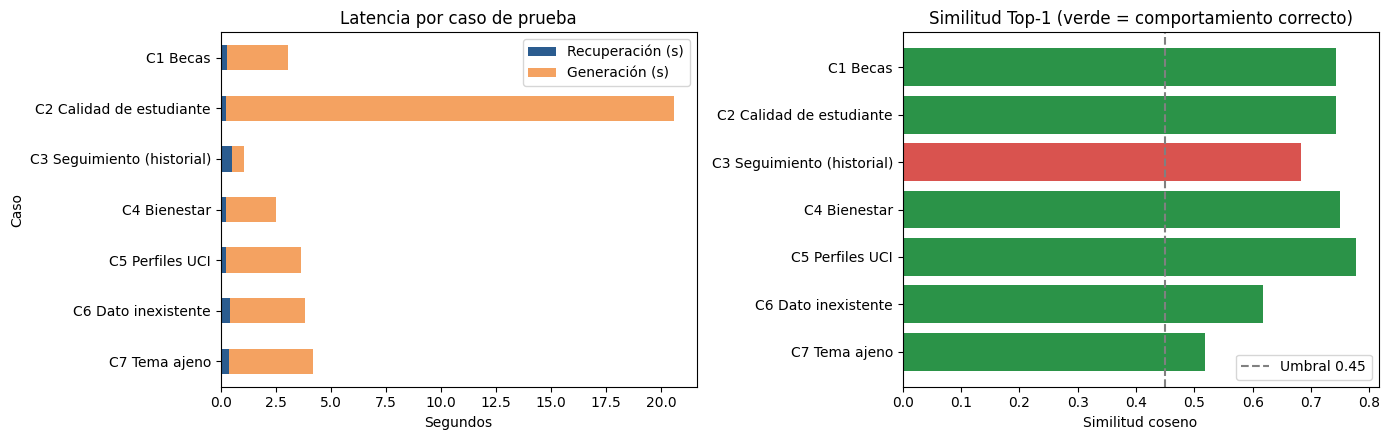

---
**Pregunta:** ¿Qué promedio necesito para obtener una beca por excelencia académica y de qué porcentaje es?

**Respuesta (gemini-3.1-flash-lite):**

Para obtener una Beca por Excelencia Académica en la CUN, se requiere cumplir con los siguientes promedios históricos y porcentajes de descuento sobre el valor ordinario de la matrícula:

*   **Promedio histórico igual o superior a 4.5:** Se otorga una beca del 50% del valor ordinario de la matrícula [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].
*   **Promedio histórico igual o superior a 4.3:** Se otorga una beca del 25% del valor ordinario de la matrícula [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].

**Requisitos adicionales:**
*   Aplica para estudiantes que ingresen del segundo semestre en adelante [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].
*   Haber cursado el máximo de créditos permitido por periodo académico [DOC-reglamento-bienestar-067].
*   No haber cancelado ni reprobado ningún crédito [DOC-reglamento-bienestar-067].
*   Encontrarse a paz y salvo financieramente en el periodo vigente [DOC-reglamento-bienestar-067].

⏱️ Total **3.04 s** (recuperación 0.27 s · generación 2.77 s) · citas válidas **3/3**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.7432,DOC-reglamento-bienestar-066,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 32,True
1,2,0.7381,DOC-resolucion-007-2024-becas-rendimiento-academico-007,Resolución Rectoral No. 007 de 2024,Preámbulo,True
2,3,0.7361,DOC-reglamento-bienestar-067,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 32,True
3,4,0.7222,DOC-reglamento-bienestar-079,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 34,True


---
**Pregunta:** ¿En qué casos se pierde la calidad de estudiante en la CUN?

**Respuesta (gemini-3.1-flash-lite):**

La calidad de estudiante en la CUN se pierde en los siguientes eventos:

*   Cuando no se renueva la matrícula dentro de los plazos establecidos por la Institución, de acuerdo con el calendario académico, o cuando se permanece inactivo académicamente por más de tres años [DOC-reglamento-estudiantil-005].
*   Cuando se procede a la cancelación de la matrícula por razones académicas o disciplinarias, previo el trámite del debido proceso [DOC-reglamento-estudiantil-005].
*   Cuando el estudiante se retira voluntariamente de la Institución [DOC-reglamento-estudiantil-005].
*   Cuando se ha finalizado la totalidad del plan de estudios para el cual se matriculó [DOC-reglamento-estudiantil-005].

⏱️ Total **20.59 s** (recuperación 0.23 s · generación 20.35 s) · citas válidas **1/1**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.7436,DOC-reglamento-estudiantil-024,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO QUINTO — RETIROS Y APLAZAMIENTOS | Artículo 14,True
1,2,0.7318,DOC-reglamento-estudiantil-005,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO PRIMERO — OBJETO Y DE LA CALIDAD DE ESTUDIANTE | Artículo 3,True
2,3,0.7282,DOC-reglamento-estudiantil-004,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO PRIMERO — OBJETO Y DE LA CALIDAD DE ESTUDIANTE | Artículo 2,True
3,4,0.7140,DOC-reglamento-estudiantil-007,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO SEGUNDO — REQUISITOS DE INSCRIPCIÓN Y ADMISIÓN | Artículo 4,True


---
**Pregunta:** ¿Y qué pasa si mi promedio queda por debajo de la nota mínima aprobatoria?

*Búsqueda reformulada:* ¿Qué sucede en la CUN si el promedio académico de un estudiante queda por debajo de la nota mínima aprobatoria?

**Respuesta (gemini-3.1-flash-lite):**

La evidencia recuperada no contiene información sobre las consecuencias académicas específicas de obtener un promedio por debajo de la nota mínima aprobatoria.

⏱️ Total **3.0 s** (recuperación 0.5 s · generación 0.58 s) · citas válidas **0/0**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.6828,DOC-reglamento-estudiantil-085,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 47,True
1,2,0.6770,DOC-reglamento-estudiantil-024,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO QUINTO — RETIROS Y APLAZAMIENTOS | Artículo 14,True
2,3,0.6756,DOC-reglamento-estudiantil-130,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO PRIMERO PRINCIPIOS RECTORES | Artículo 63,True
3,4,0.6729,DOC-reglamento-estudiantil-051,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO NOVENO | Artículo 28,True


... (4 outputs left out)

---
**Pregunta:** ¿Cuánto paga la CUN de auxilio mensual de transporte en helicóptero?

**Respuesta (gemini-3.1-flash-lite):**

La evidencia recuperada no contiene información sobre esa consulta.

⏱️ Total **3.85 s** (recuperación 0.42 s · generación 3.43 s) · citas válidas **0/0**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.6184,DOC-reglamento-estudiantil-057,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,CAPÍTULO NOVENO | Artículo 31,True
1,2,0.6083,DOC-resolucion-007-2024-becas-rendimiento-academico-001,Resolución Rectoral No. 007 de 2024,Preámbulo,True
2,3,0.5970,DOC-reglamento-bienestar-075,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 33,True
3,4,0.5927,DOC-reglamento-bienestar-055,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Preámbulo,True


---
**Pregunta:** ¿Quién ganó el mundial de fútbol de 2022?

**Respuesta (gemini-3.1-flash-lite):**

Esta consulta está fuera del alcance del asistente, ya que mi función es brindar información sobre la normatividad, bienestar institucional, becas y permanencia estudiantil de la CUN.

⏱️ Total **4.2 s** (recuperación 0.4 s · generación 3.8 s) · citas válidas **0/0**

,rank,similitud,id,fuente,ubicacion,supera_umbral
0,1,0.5177,DOC-reglamento-bienestar-104,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO OCTAVO | Artículo 48,True
1,2,0.5136,DOC-reglamento-bienestar-076,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 33,True
2,3,0.5119,DOC-reglamento-bienestar-103,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO OCTAVO | Artículo 48,True
3,4,0.5115,DOC-reglamento-bienestar-075,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,CAPÍTULO SEPTIMO | Artículo 33,True


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

tabla_eval.set_index("Caso")[["Recuperación (s)", "Generación (s)"]].plot(
    kind="barh", stacked=True, color=["#2b5c8f", "#f4a261"], ax=axes[0])
axes[0].set_title("Latencia por caso de prueba")
axes[0].set_xlabel("Segundos")
axes[0].invert_yaxis()

colores = ["#2b9348" if ok else "#d9534f" for ok in tabla_eval["Comportamiento correcto"]]
axes[1].barh(tabla_eval["Caso"], tabla_eval["Similitud Top-1"], color=colores)
axes[1].axvline(rag.UMBRAL_SIMILITUD, ls="--", color="gray", label=f"Umbral {rag.UMBRAL_SIMILITUD}")
axes[1].set_title("Similitud Top-1 (verde = comportamiento correcto)")
axes[1].set_xlabel("Similitud coseno")
axes[1].invert_yaxis()
axes[1].legend()

plt.tight_layout()
plt.show()

for r in resultados_eval:
    mostrar(r)

### Interpretación de los resultados

> **Resultado global:** 6 de 7 casos con comportamiento correcto (**86%**), **100%** de citas válidas y una latencia promedio de **5.83 s** (3.37 s si se excluye el caso C2, afectado por una espera de cuota de la API).

1. **Precisión contextual.** En las consultas normativas la similitud Top-1 fue de **0.7432** (C1), **0.7436** (C2) y **0.7491** (C4), y los cuatro fragmentos recuperados en cada caso superaron el umbral. La recuperación trajo los artículos pertinentes: en C1, el Artículo 32 del Reglamento de Bienestar y la Resolución Rectoral 007 de 2024 (becas del 50% con promedio ≥ 4.5 y del 25% con promedio ≥ 4.3); en C2, el Artículo 3 del Reglamento Estudiantil (calidad de estudiante); y en C4, los Artículos 15, 21 y 24 del Reglamento de Bienestar. En C5, el filtro por tipo de fuente devolvió cuatro perfiles de Ingeniería Informática (similitud 0.76–0.78), y el modelo seleccionó el perfil EST-2317, que reúne exactamente las condiciones consultadas: matrícula en mora, 40% de aprobación en primer semestre, alerta de riesgo alto y resultado final de deserción.

2. **Fidelidad.** El **100%** de las citas generadas (9 en total en C1, C2, C4 y C5) corresponde a fragmentos realmente recuperados de Qdrant Cloud. El modelo no inventó identificadores ni cifras: los promedios y porcentajes de la respuesta de becas coinciden textualmente con la normativa.

3. **Historial conversacional.** En C3 la pregunta de seguimiento "¿Y qué pasa si mi promedio queda por debajo de la nota mínima aprobatoria?" se reformuló correctamente como "¿Qué sucede en la CUN si el promedio académico de un estudiante queda por debajo de la nota mínima aprobatoria?". Sin embargo, el Top-4 recuperó artículos cercanos pero no el específico (similitud Top-1 de 0.6828, Artículo 47 sobre evaluación y calificación), y el asistente respondió que la evidencia no contenía esa información. Es el único caso incorrecto, pero el error es **seguro**: el sistema prefirió abstenerse antes que inventar una consecuencia académica. Se identifica como oportunidad de mejora aumentar el Top-k o incorporar búsqueda híbrida (léxica + vectorial).

4. **Robustez fuera de contexto.** En C6 (auxilio en helicóptero) el asistente respondió que la evidencia no contiene esa información, y en C7 (mundial de fútbol) indicó que la consulta está fuera de su alcance. Las similitudes Top-1 fueron de 0.6184 y 0.5177, ambas por encima del umbral de 0.45, por lo que la abstención se logró gracias a las **reglas del prompt de sistema** y no al filtro de similitud. Un umbral más alto (≈ 0.65) evitaría la llamada al LLM en estos casos, a costa de arriesgar consultas válidas con similitud cercana.

5. **Latencia.** La recuperación en Qdrant Cloud es estable y rápida (promedio de **0.33 s**). La generación concentra la mayor parte del tiempo (promedio de **2.70 s** sin C2). El caso C2 (20.59 s) corresponde a una espera por el límite de solicitudes de la capa gratuita de Gemini y no a la complejidad de la consulta. Como optimización, priorizar el modelo `gemini-3.1-flash-lite` (mayor cuota gratuita) redujo la latencia de la prueba de conexión de **71.09 s a 0.51 s**.

---
## 7. Conclusiones

1. **Integración end-to-end.** Se completó el ciclo RAG sobre la base vectorial del ACA 1: Qdrant Cloud almacena **360 fragmentos** (300 normativos de la CUN y 60 perfiles estudiantiles del dataset UCI #697) y Gemini redacta las respuestas en lenguaje natural. Todo el sistema funciona sobre capas gratuitas de servicios en la nube, sin infraestructura propia.
2. **Respuestas fundamentadas.** El **100%** de las citas generadas corresponde a fragmentos realmente recuperados, y las cifras reportadas (por ejemplo, becas del 50% con promedio ≥ 4.5 y del 25% con promedio ≥ 4.3) coinciden textualmente con la normativa. Las reglas del prompt de sistema y la exigencia de citas `[ID]` reducen las alucinaciones.
3. **Robustez y comportamiento seguro.** El sistema tuvo un comportamiento correcto en **6 de 7 casos (86%)**. Ante consultas sin evidencia (auxilio en helicóptero) o ajenas al dominio (mundial de fútbol), el asistente se abstuvo en lugar de inventar. El único caso fallido (C3) también terminó en abstención, lo que confirma que el sistema prefiere reconocer la falta de evidencia antes que generar información no respaldada.
4. **Memoria conversacional.** La reformulación de preguntas con el historial convierte consultas de seguimiento ("¿y qué pasa si...?") en preguntas autónomas. Su efectividad depende de que la recuperación encuentre el artículo exacto, lo que en C3 no ocurrió con un Top-k de 4.
5. **Desempeño en la nube.** La recuperación en Qdrant Cloud es rápida y estable (≈ 0.33 s en promedio), mientras que la generación concentra la mayor parte de la latencia (≈ 2.7 s). La elección del modelo resultó determinante: priorizar `gemini-3.1-flash-lite`, con mayor cuota gratuita, redujo el tiempo de respuesta de la prueba de conexión de 71.09 s a 0.51 s.
6. **Gestión documental y seguridad.** La interfaz en Streamlit permite supervisar el índice vectorial, probar la recuperación y agregar o eliminar documentos sin modificar el código. Las credenciales se gestionan con *secrets* y `.env`, nunca en el código, y el repositorio incluye `requirements.txt`, README y un módulo único compartido por el notebook y la app.
7. **Limitaciones y trabajo futuro.** La calidad de las respuestas depende de la cobertura del corpus y de las cuotas de la capa gratuita, que pueden generar esperas ocasionales (caso C2, 20.59 s). Como mejoras se proponen aumentar el Top-k o aplicar *re-ranking* de fragmentos, incorporar búsqueda híbrida (léxica + vectorial) y ajustar el umbral de similitud para descartar consultas fuera de contexto sin llamar al LLM.

---
## Referencias

- Google. (2025). *Gemini API documentation*. https://ai.google.dev/gemini-api/docs
- Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems, 33*, 9459–9474. https://arxiv.org/abs/2005.11401
- Qdrant Solutions GmbH. (2024). *Qdrant documentation: Vector search engine & cloud database*. https://qdrant.tech/documentation/
- Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict students' dropout and academic success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89
- Streamlit Inc. (2024). *Streamlit documentation: Build and share data apps*. https://docs.streamlit.io/
